---
title: "Legendre Transforms, Phase Portraits and Hyperbolic Functions"
short_title: "M7 Legendre & Phase Space"
numbering:
  heading_2: true
  equation: true
---

# Legendre Transforms, Phase Portraits and Hyperbolic Functions

:::{tip} Where this sits in the plan
Math for **Hamiltonian mechanics** (Legendre transform, phase portraits) and **special relativity** (hyperbolic functions, rapidity).

| Item | Stewart | Boas | Zill | Other |
|---|---|---|---|---|
| Legendre transform | – | 4 (partial derivatives) | – | Taylor 13, Schroeder 1/5 |
| Nonlinear systems and phase portraits | – | 8 | 11 | – |
| Hyperbolic functions | 3 | 2 | – | – |

Chapter numbers are approximate, as in the workbook.
:::

Three unrelated-looking tools that the last two mechanics topics depend on. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp, quad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
g = 9.81  # m/s^2

## The Legendre Transform

Sometimes a function $f(x)$ is known, but the natural variable for the problem is its slope $p = f'(x)$ rather than $x$. Simply substituting $x(p)$ into $f$ loses information: $f(x)$ and $f(x + c)$ give the same function of slope. The **Legendre transform** keeps all the information.

:::{prf:definition} Legendre transform
:label: def-legendre

For a convex function $f(x)$, define $p = f'(x)$ and

$$
g(p) = p\,x - f(x), \qquad\text{with } x = x(p) \text{ from } p = f'(x) .
$$ (eq-legendre)
:::

**Geometric meaning.** A convex curve is determined by its tangent lines. The tangent with slope $p$ crosses the vertical axis at height $f(x) - px = -g(p)$. So $g(p)$ records the intercept of the tangent line of each slope, an equivalent description of the same curve.

**The key property.** Differentiate {eq}`eq-legendre` and use $p = f'(x)$:

$$
dg = x\,dp + p\,dx - f'(x)\,dx = x\,dp \quad\Longrightarrow\quad \frac{dg}{dp} = x .
$$

The roles swap symmetrically: $f'(x) = p$ and $g'(p) = x$. Transforming $g$ again gives back $f$.

**With extra variables.** If $f(x, y)$ and only $x$ is transformed, then $g(p, y) = px - f$ and $\partial g/\partial y = -\partial f/\partial y$. Passive variables just flip sign. This is exactly the relation $\partial H/\partial q = -\partial\mathcal{L}/\partial q$ in Hamiltonian mechanics.

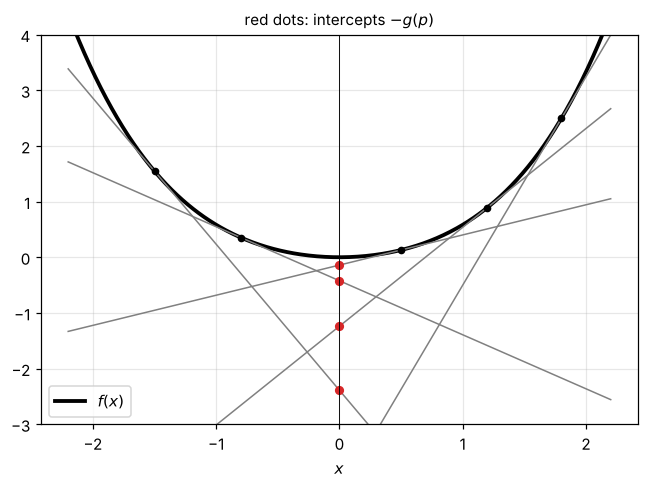

In [2]:
#| label: fig-legendre
#| caption: The Legendre transform as tangent lines. For f(x) = x²/2 + x⁴/12, each tangent of slope p (gray) meets the vertical axis at −g(p). The family of intercepts describes the curve as completely as f itself.
f = lambda x: x**2 / 2 + x**4 / 12
fp = lambda x: x + x**3 / 3
x = np.linspace(-2.2, 2.2, 400)
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.plot(x, f(x), "k", lw=2.5, label="$f(x)$")
for x0 in [-1.5, -0.8, 0.5, 1.2, 1.8]:
    p = fp(x0); icpt = f(x0) - p * x0
    ax.plot(x, f(x0) + p * (x - x0), color="gray", lw=1)
    ax.plot(0, icpt, "o", color="tab:red", ms=5)
    ax.plot(x0, f(x0), "o", color="k", ms=4)
ax.axvline(0, color="k", lw=0.6)
ax.set_ylim(-3, 4); ax.set_xlabel("$x$"); ax.legend(); ax.set_title(r"red dots: intercepts $-g(p)$", fontsize=10)
plt.show()

In [3]:
# Legendre transform with sympy, and the transform back
x, p, a = sp.symbols("x p a", positive=True)
f = a * x**2 / 2
x_of_p = sp.solve(sp.Eq(sp.diff(f, x), p), x)[0]
g = sp.simplify(p * x_of_p - f.subs(x, x_of_p))
print("g(p) =", g)
p_of_x = sp.solve(sp.Eq(sp.diff(g, p), x), p)[0]
print("transform back:", sp.simplify(x * p_of_x - g.subs(p, p_of_x)))

g(p) = p**2/(2*a)
transform back: a*x**2/2


:::{note} The same move in thermodynamics
Internal energy $U(S, V)$ has $\partial U/\partial S = T$. Legendre-transforming away $S$ gives the Helmholtz free energy $F(T, V) = U - TS$, the natural function when temperature is held fixed. Enthalpy and Gibbs free energy come from the same construction. Schroeder uses this throughout, so this section serves both courses.
:::

### Exercises

1. Find the Legendre transform of $f(x) = e^x$.
2. Find the Legendre transform of $f(v) = \tfrac12mv^2 + bv$ in terms of $p = f'(v)$.
3. Show that applying the transform twice to $f(x) = x^4/4$ returns $f$.

:::{dropdown} Hints
1. $p = e^x$, so $x = \ln p$.
2. $p = mv + b$.
3. $p = x^3$, so $g = \tfrac34p^{4/3}$; then transform $g$.
:::

:::{dropdown} Answers
1. $g(p) = p\ln p - p$.
2. $g = (p - b)^2/(2m)$. This is the Hamiltonian of a particle with a velocity-linear term in its Lagrangian, like the magnetic vector-potential term.
3. $g'(p) = p^{1/3} = x$, and $px - g = x^4 - \tfrac34x^4 = x^4/4$.
:::

## Nonlinear Systems and Phase Portraits

A two-dimensional autonomous system

$$
\dot x = F(x, y), \qquad \dot y = G(x, y)
$$

assigns a velocity to every point of the plane. Its **phase portrait**, the family of all trajectories, can be sketched without solving anything:

1. **Find the fixed points**, where $F = G = 0$.
2. **Linearize** at each one. With small displacements $\boldsymbol\xi$, $\dot{\boldsymbol\xi} = J\boldsymbol\xi$, where $J$ is the **Jacobian matrix** of partial derivatives $\begin{pmatrix}F_x & F_y\\ G_x & G_y\end{pmatrix}$ evaluated at the fixed point.
3. **Classify** each point by the eigenvalues of $J$ (the table in M6: node, saddle, spiral, center).
4. **Connect** the local pictures, using any conserved quantity or special curves.

:::{warning} When linearization is not enough
If the eigenvalues are purely imaginary, the linear picture is a center, but nonlinear terms can turn it into a slow spiral. For **conservative** mechanical systems (no friction), a conserved energy guarantees that centers stay centers.
:::

### The pendulum

With $x = \phi$ and $y = \dot\phi$, the pendulum is $\dot x = y$, $\dot y = -\sin x$ (in units with $g/L = 1$). The fixed points are $(n\pi, 0)$. At even multiples of $\pi$ (hanging down) $J$ has eigenvalues $\pm i$: centers. At odd multiples (balanced upright) the eigenvalues are $\pm1$: saddles. The curves joining neighboring saddles, the **separatrices**, divide back-and-forth swinging from motion all the way around.

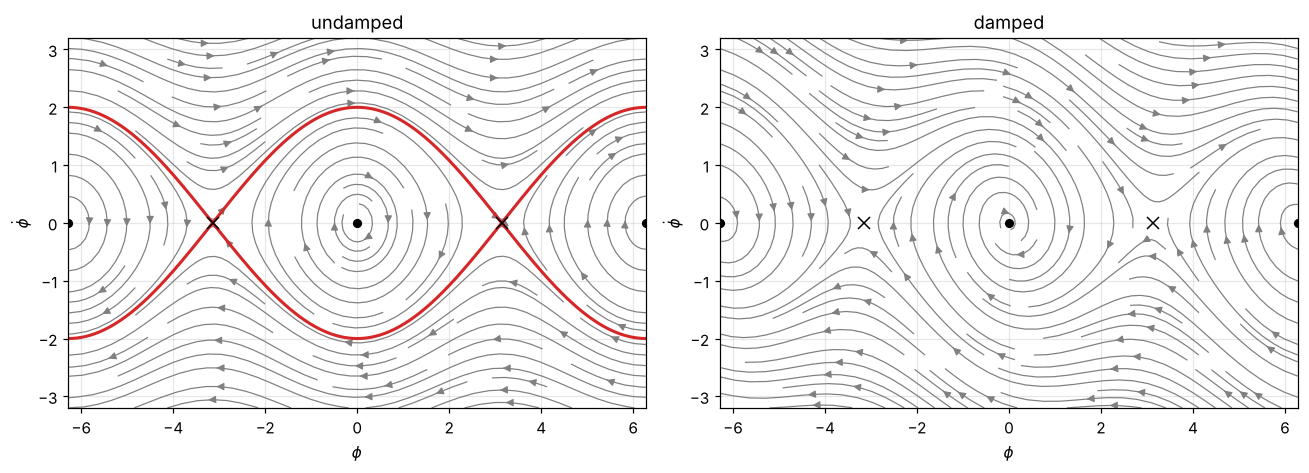

In [4]:
#| label: fig-pendulum-portrait
#| caption: Phase portraits of the pendulum. Left, undamped: closed orbits (swinging) inside the red separatrices, open curves (rotating) outside. Right, with damping: the centers become stable spirals, and almost every trajectory ends hanging at rest.
x = np.linspace(-2 * np.pi, 2 * np.pi, 400)
y = np.linspace(-3.2, 3.2, 300)
X, Y = np.meshgrid(x, y)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].streamplot(X, Y, Y, -np.sin(X), density=1.2, color="gray", linewidth=0.8)
xs = np.linspace(-2 * np.pi, 2 * np.pi, 800)
sep = 2 * np.abs(np.cos(xs / 2))
axes[0].plot(xs, sep, "tab:red", lw=2); axes[0].plot(xs, -sep, "tab:red", lw=2)
axes[0].set_title("undamped")
axes[1].streamplot(X, Y, Y, -np.sin(X) - 0.25 * Y, density=1.2, color="gray", linewidth=0.8)
axes[1].set_title("damped")
for ax in axes:
    ax.plot([-2 * np.pi, 0, 2 * np.pi], [0, 0, 0], "ko", ms=5)
    ax.plot([-np.pi, np.pi], [0, 0], "kx", ms=8)
    ax.set_xlabel(r"$\phi$"); ax.set_ylabel(r"$\dot\phi$")
plt.tight_layout(); plt.show()

### Limit cycles

Nonlinear systems can do something linear ones cannot: settle onto an isolated closed orbit, a **limit cycle**, whose size is set by the system itself rather than the initial conditions. The classic example is the **van der Pol oscillator**,

$$
\ddot x - \mu\left(1 - x^2\right)\dot x + x = 0 ,
$$

which has negative damping for small $|x|$ (it pumps energy in) and positive damping for large $|x|$ (it drains energy out). Every trajectory approaches the same cycle. Heartbeats, some variable stars, and electronic oscillators behave this way.

In two dimensions, trajectories cannot cross, which limits what can happen: bounded motion ends at a fixed point, on a closed orbit, or on a limit cycle (the Poincaré–Bendixson theorem). **Chaos needs at least three dimensions**, for example a pendulum with a periodic drive, where time itself acts as the third variable.

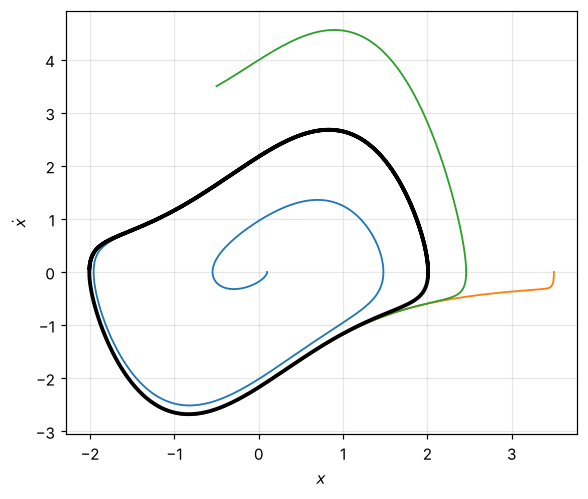

In [5]:
#| label: fig-van-der-pol
#| caption: The van der Pol oscillator with μ = 1. Trajectories starting inside and outside (colored) all converge to the same limit cycle (black).
mu = 1.0
rhs = lambda t, s: [s[1], mu * (1 - s[0]**2) * s[1] - s[0]]
fig, ax = plt.subplots(figsize=(6, 5))
for s0, c in [([0.1, 0], "tab:blue"), ([3.5, 0], "tab:orange"), ([-0.5, 3.5], "tab:green")]:
    sol = solve_ivp(rhs, (0, 25), s0, max_step=0.01)
    ax.plot(sol.y[0], sol.y[1], color=c, lw=1.2)
late = solve_ivp(rhs, (0, 60), [2, 0], t_eval=np.linspace(50, 60, 2000), max_step=0.01)
ax.plot(late.y[0], late.y[1], "k", lw=2.5)
ax.set_xlabel("$x$"); ax.set_ylabel(r"$\dot x$"); plt.show()

### Exercises

1. Find and classify the fixed points of $\dot x = y$, $\dot y = x - x^3$ (a particle in a double-well potential).
2. For the damped pendulum $\dot x = y$, $\dot y = -\sin x - \gamma y$, find the eigenvalues at $(0, 0)$ and say when it is a spiral and when a node.

:::{dropdown} Hints
1. The fixed points are at $y = 0$, $x = 0, \pm1$. Compute $J$ at each.
2. $J = \begin{pmatrix}0 & 1\\ -1 & -\gamma\end{pmatrix}$.
:::

:::{dropdown} Answers
1. $(0,0)$: eigenvalues $\pm1$, a saddle (the hump). $(\pm1, 0)$: eigenvalues $\pm i\sqrt2$, centers (the well bottoms), which stay centers because energy is conserved.
2. $\lambda = \tfrac12\left(-\gamma\pm\sqrt{\gamma^2 - 4}\right)$: a stable spiral for $\gamma < 2$ (underdamped) and a stable node for $\gamma > 2$ (overdamped), matching M4.
:::

## Hyperbolic Functions

$$
\cosh u = \frac{e^u + e^{-u}}{2}, \qquad \sinh u = \frac{e^u - e^{-u}}{2}, \qquad \tanh u = \frac{\sinh u}{\cosh u} .
$$

They mirror the trigonometric functions with a few sign changes:

| Trigonometric | Hyperbolic |
|---|---|
| $\cos^2\theta + \sin^2\theta = 1$ | $\cosh^2u - \sinh^2u = 1$ |
| $\frac{d}{d\theta}\sin\theta = \cos\theta$, $\frac{d}{d\theta}\cos\theta = -\sin\theta$ | $\frac{d}{du}\sinh u = \cosh u$, $\frac{d}{du}\cosh u = \sinh u$ |
| $(\cos\theta, \sin\theta)$ traces a circle | $(\cosh u, \sinh u)$ traces the hyperbola $x^2 - y^2 = 1$ |
| $\tan(a + b) = \dfrac{\tan a + \tan b}{1 - \tan a\tan b}$ | $\tanh(a + b) = \dfrac{\tanh a + \tanh b}{1 + \tanh a\tanh b}$ |

The inverses are logarithms, for example $\tanh^{-1}y = \tfrac12\ln\dfrac{1 + y}{1 - y}$.

They have already appeared several times: falling with quadratic drag ($\tanh$), the hanging chain ($\cosh$), and the bead on a rotating wire ($\cosh$). In special relativity they become central. A Lorentz boost is a "rotation" that preserves $c^2t^2 - x^2$ instead of $x^2 + y^2$, so it is written with $\cosh$ and $\sinh$ of a **rapidity** $u$, with velocity $v = c\tanh u$. The $\tanh$ addition formula above is then exactly the relativistic velocity-addition rule.

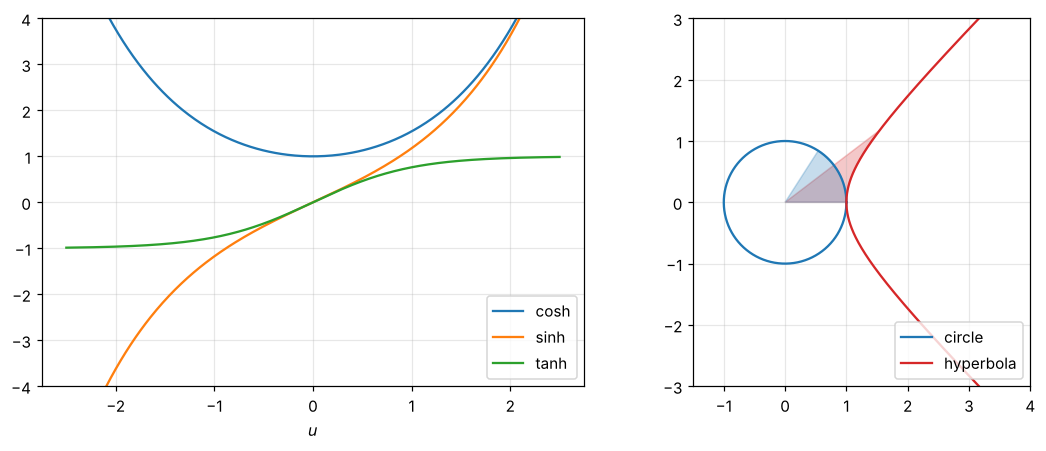

In [6]:
#| label: fig-hyperbolic
#| caption: Left, cosh, sinh and tanh. Right, (cos θ, sin θ) traces a circle and (cosh u, sinh u) traces a hyperbola; in both the parameter is twice the shaded area swept from the x-axis.
u = np.linspace(-2.5, 2.5, 400)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
axes[0].plot(u, np.cosh(u), label="cosh"); axes[0].plot(u, np.sinh(u), label="sinh"); axes[0].plot(u, np.tanh(u), label="tanh")
axes[0].set_ylim(-4, 4); axes[0].legend(); axes[0].set_xlabel("$u$")
th = np.linspace(0, 2 * np.pi, 300)
axes[1].plot(np.cos(th), np.sin(th), "tab:blue", label="circle")
axes[1].plot(np.cosh(u), np.sinh(u), "tab:red", label="hyperbola")
uu = np.linspace(0, 1.0, 100)
axes[1].fill(np.r_[0, np.cosh(uu), 0], np.r_[0, np.sinh(uu), 0], color="tab:red", alpha=0.25)
tt = np.linspace(0, 1.0, 100)
axes[1].fill(np.r_[0, np.cos(tt), 0], np.r_[0, np.sin(tt), 0], color="tab:blue", alpha=0.25)
axes[1].set_aspect("equal"); axes[1].set_xlim(-1.5, 4); axes[1].set_ylim(-3, 3); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

### Exercises

1. Prove $\cosh^2u - \sinh^2u = 1$ from the definitions.
2. Show that if $v_1 = c\tanh u_1$ and $v_2 = c\tanh u_2$, then $\tanh(u_1 + u_2) = \dfrac{v_1 + v_2}{c\,(1 + v_1v_2/c^2)}$. Evaluate for $v_1 = v_2 = 0.8c$.
3. Solve $\ddot r = \omega^2r$ with $r(0) = r_0$, $\dot r(0) = 0$ using hyperbolic functions.

:::{dropdown} Hints
1. Square the definitions and subtract.
2. Use the addition formula in the table.
3. The solutions are $\cosh\omega t$ and $\sinh\omega t$.
:::

:::{dropdown} Answers
1. $\tfrac14\left[(e^u + e^{-u})^2 - (e^u - e^{-u})^2\right] = \tfrac14\cdot4 = 1$.
2. Substituting gives the formula; $1.6c/(1 + 0.64) \approx 0.976c$, still less than $c$.
3. $r = r_0\cosh\omega t$.
:::

## Summary

- The Legendre transform $g(p) = px - f(x)$ trades a variable for its slope without losing information; $g'(p) = x$, and passive variables flip sign.
- Phase portraits come from fixed points, Jacobian eigenvalues and global structure; conservative systems have centers and saddles joined by separatrices.
- Nonlinear systems can have limit cycles; chaos needs at least three dimensions.
- Hyperbolic functions are the "trig functions" of the hyperbola, with $\cosh^2 - \sinh^2 = 1$, and their addition formula is relativistic velocity addition.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.